In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/output_data.csv')
df

,Item Code,Quantity,Price
0,ASMB-R1,86490,225.0
1,ASMB-R2,500,375.0
2,ASMB-R3,26000,225.0
3,ASMB-R4,12500,168.0
4,ASMB-R5,578000,252.0
...,...,...,...
135,ASMB-R136,10745,538.2
136,ASMB-R137,42543,178.2
137,ASMB-R138,18768,216.0
138,ASMB-R139,113620,100.8


In [ ]:
item_col = df.columns[0]
quantity_col = df.columns[1]
price_col = df.columns[2]

In [ ]:
df['consumption_value'] = df[quantity_col]*df[price_col]
df.sort_values(by ='consumption_value', ascending = False, inplace = True)
df.head()

,Item Code,Quantity,Price,consumption_value
121,ASMB-R122,525070,441.0,231555870.0
74,ASMB-R75,653150,302.4,197512560.0
51,ASMB-R52,464655,367.5,170760712.5
104,ASMB-R105,307619,504.0,155039976.0
4,ASMB-R5,578000,252.0,145656000.0


In [ ]:
total_consumption_value = df['consumption_value'].sum()

In [ ]:
df['item_percentage']= (df['consumption_value']/(total_consumption_value))*100
df.head()

,Item Code,Quantity,Price,consumption_value,item_percentage
121,ASMB-R122,525070,441.0,231555870.0,7.464984
74,ASMB-R75,653150,302.4,197512560.0,6.367483
51,ASMB-R52,464655,367.5,170760712.5,5.505047
104,ASMB-R105,307619,504.0,155039976.0,4.998236
4,ASMB-R5,578000,252.0,145656000.0,4.695712


In [ ]:
df['cumulative_percentage'] = df['item_percentage'].cumsum()
df.head()

,Item Code,Quantity,Price,consumption_value,item_percentage,cumulative_percentage
121,ASMB-R122,525070,441.0,231555870.0,7.464984,7.464984
74,ASMB-R75,653150,302.4,197512560.0,6.367483,13.832467
51,ASMB-R52,464655,367.5,170760712.5,5.505047,19.337514
104,ASMB-R105,307619,504.0,155039976.0,4.998236,24.335751
4,ASMB-R5,578000,252.0,145656000.0,4.695712,29.031463


In [ ]:
import numpy as np
df['categories'] = np.where(df['cumulative_percentage'] <= 70 , 'A' , np.where(df['cumulative_percentage'] <= 90 , 'B' , 'C'))
df.head()


,Item Code,Quantity,Price,consumption_value,item_percentage,cumulative_percentage,categories
121,ASMB-R122,525070,441.0,231555870.0,7.464984,7.464984,A
74,ASMB-R75,653150,302.4,197512560.0,6.367483,13.832467,A
51,ASMB-R52,464655,367.5,170760712.5,5.505047,19.337514,A
104,ASMB-R105,307619,504.0,155039976.0,4.998236,24.335751,A
4,ASMB-R5,578000,252.0,145656000.0,4.695712,29.031463,A


In [ ]:
A_items = df[df['categories']=='A'].drop(columns = ['consumption_value','item_percentage','cumulative_percentage'])
A_items.value_counts('categories')

,count
categories,
A,21


In [ ]:
B_items = df[df['categories']=='B'].drop(columns = ['consumption_value','item_percentage','cumulative_percentage'])
B_items.value_counts('categories')

,count
categories,
B,27


In [ ]:
C_items = df[df['categories']=='C'].drop(columns = ['consumption_value','item_percentage','cumulative_percentage'])
C_items.value_counts('categories')

,count
categories,
C,92


we can list the A,B,C items

In [ ]:
A_items

,Item Code,Quantity,Price,categories
121,ASMB-R122,525070,441.00,A
74,ASMB-R75,653150,302.40,A
51,ASMB-R52,464655,367.50,A
104,ASMB-R105,307619,504.00,A
4,ASMB-R5,578000,252.00,A
107,ASMB-R108,779427,176.40,A
134,ASMB-R135,255474,459.00,A
34,ASMB-R35,272221,420.00,A
120,ASMB-R121,107009,959.40,A
37,ASMB-R38,689750,147.00,A


In [17]:
B_items

,Item Code,Quantity,Price,categories
48,ASMB-R49,182700,234.0,B
47,ASMB-R48,114900,360.0,B
129,ASMB-R130,495515,81.0,B
33,ASMB-R34,70000,487.5,B
60,ASMB-R61,201000,166.5,B
49,ASMB-R50,113200,285.0,B
59,ASMB-R60,438500,67.5,B
128,ASMB-R129,109365,261.0,B
123,ASMB-R124,79658,342.0,B
70,ASMB-R71,97743,270.0,B


In [18]:
C_items

,Item Code,Quantity,Price,categories
87,ASMB-R88,63309,199.8,C
30,ASMB-R31,824000,15.0,C
106,ASMB-R107,37921,316.8,C
138,ASMB-R139,113620,100.8,C
27,ASMB-R28,151600,66.0,C
...,...,...,...,...
9,ASMB-R10,200,397.5,C
88,ASMB-R89,193,142.2,C
139,ASMB-R140,1253,16.2,C
18,ASMB-R19,162,118.5,C


In [21]:
N = len(df)

df['Cumulative Items %'] = (
    np.arange(1, N + 1) / N
) * 100

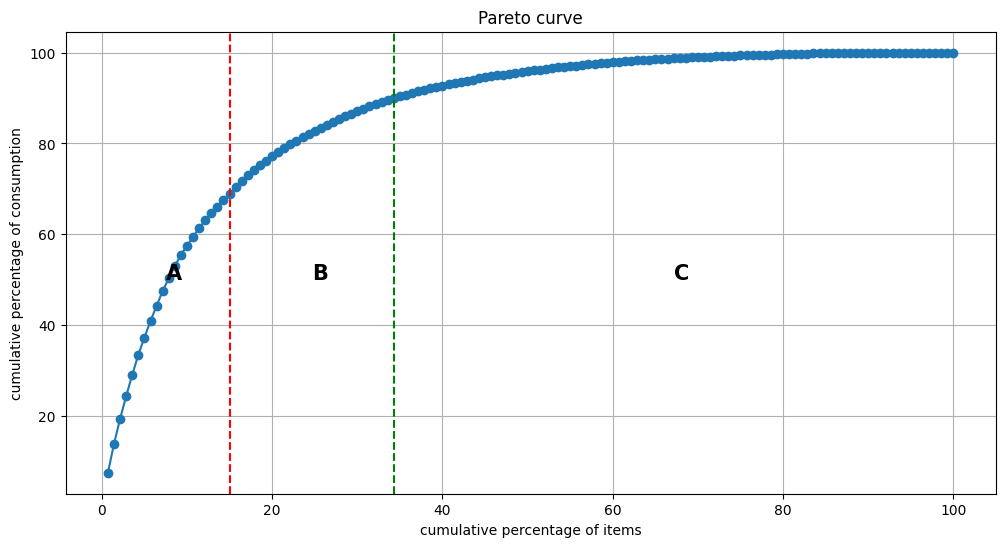

In [32]:
a_end = df.loc[
    df['categories'] == 'A',
    'Cumulative Items %'
].max()

b_end = df.loc[
    df['categories'].isin(['A', 'B']),
    'Cumulative Items %'
].max()
plt.figure(figsize=(12,6))
plt.plot(
    df['Cumulative Items %'],
    df['cumulative_percentage'],
    marker= 'o'
)
plt.xlabel('cumulative percentage of items')
plt.ylabel('cumulative percentage of consumption')
plt.title('Pareto curve')
plt.grid(True)
plt.axvline(a_end, color='red', linestyle='--')
plt.axvline(b_end, color='green', linestyle='--')

# Zone labels
plt.text(a_end/2, 50, 'A', fontsize=15, fontweight='bold')
plt.text((a_end+b_end)/2, 50, 'B', fontsize=15, fontweight='bold')
plt.text((b_end+100)/2, 50, 'C', fontsize=15, fontweight='bold')


plt.show()



In [23]:
df

,Item Code,Quantity,Price,consumption_value,item_percentage,cumulative_percentage,categories,Cumulative Items %
121,ASMB-R122,525070,441.0,231555870.0,7.464984,7.464984,A,0.714286
74,ASMB-R75,653150,302.4,197512560.0,6.367483,13.832467,A,1.428571
51,ASMB-R52,464655,367.5,170760712.5,5.505047,19.337514,A,2.142857
104,ASMB-R105,307619,504.0,155039976.0,4.998236,24.335751,A,2.857143
4,ASMB-R5,578000,252.0,145656000.0,4.695712,29.031463,A,3.571429
...,...,...,...,...,...,...,...,...
9,ASMB-R10,200,397.5,79500.0,0.002563,99.997363,C,97.142857
88,ASMB-R89,193,142.2,27444.6,0.000885,99.998248,C,97.857143
139,ASMB-R140,1253,16.2,20298.6,0.000654,99.998902,C,98.571429
18,ASMB-R19,162,118.5,19197.0,0.000619,99.999521,C,99.285714


In [33]:
a_end

15.0

In [25]:
b_end

34.285714285714285

<Axes: xlabel='categories'>

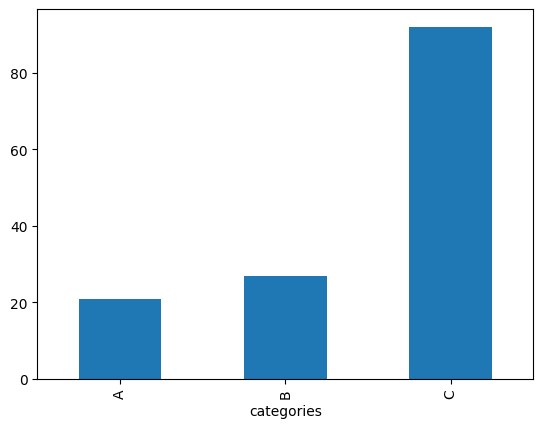

In [36]:
 df.groupby('categories')['Item Code'].count().plot(kind ='bar')

<Axes: ylabel='consumption_value'>

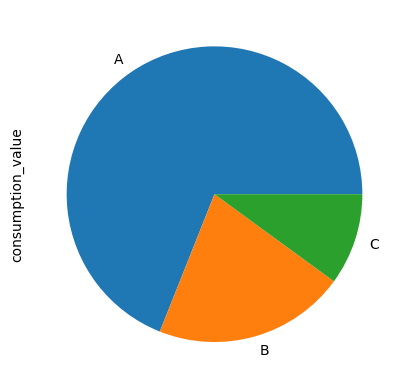

In [37]:
df.groupby('categories')['consumption_value'].sum().plot(kind ='pie')